# Tropical Pacific SST: Anomaly and EOF Analysis

**Dataset:** ERA5 monthly averaged sea-surface temperature (SST)  
**Analysis period:** January 1961–December 2020  
**Region:** 20°S–20°N, 120°E–80°W

## Objective
Calculate monthly SST anomalies, extract the leading three Empirical Orthogonal Functions (EOFs) and their Principal Components (PCs), and quantify the variance explained by each mode.

> This notebook is part of coursework for Climate Data Analysis and Methods.

## 1. Import libraries

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

c:\Users\thean\anaconda3\envs\thesis\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 2. Load ERA5 data

In [2]:
from pathlib import Path

# Set this to the directory containing the downloaded ERA5 files.
DATA_DIR = Path("data")
SST_FILE = DATA_DIR / "SST" / "data_stream-moda_stepType-avgua.nc"

if not SST_FILE.exists():
    raise FileNotFoundError(
        f"ERA5 SST file not found: {SST_FILE}. Update DATA_DIR or place the file there."
    )

ds = xr.open_dataset(SST_FILE)

## 3. Select region and time period

In [3]:
#Extract the sst variable
sst = ds['sst']

#Restricting to given Tropical Pacific(20◦S-20◦N,120◦E–80◦W)
#In ERA5 Dataset the longitude will be 0 to 360, so (120,360-80)
sst = sst.sel(latitude=slice(20, -20), longitude=slice(120, 280))

#Restricting to the given time period (1961-2020)
#The downloaded file starts from 1940, so this selection is needed
sst = sst.sel(valid_time=slice("1961-01-01", "2020-12-31"))
print("Time range:", sst.valid_time.values[0], "to", sst.valid_time.values[-1])

Time range: 1961-01-01T00:00:00.000000000 to 2020-12-01T00:00:00.000000000


## 4. Monthly climatology and anomalies

In [4]:
#Here I am computing monthly climatology
climatology = sst.groupby("valid_time.month").mean("valid_time")

#Subtracting climatology to get SST anomalies
sst_anomaly = sst.groupby("valid_time.month") - climatology

## 5. EOF analysis

The anomalies are weighted by the square root of cos(latitude) so that each grid cell contributes in proportion to its area. Land points are excluded, the data are centred, and the EOFs are obtained by singular value decomposition (SVD).

In [5]:
#Applied sqrt(cos(lat)) weighting to account for grid cell area differences
W = np.sqrt(np.cos(np.deg2rad(sst_anomaly.coords['latitude'].values)))
X = sst_anomaly * W[np.newaxis,:,np.newaxis]

In [6]:
#Getting sizes for reshaping
ntime = X.sizes["valid_time"]
nlat = X.sizes["latitude"]
nlon = X.sizes["longitude"]

#Reshaped 3D into 2D
X2D = X.values.reshape(ntime, nlat * nlon)

In [7]:
#Handling NAN values (land points are NaN at all times)
#Finding the land mask first, so the mean is taken only over ocean points
mask = np.isnan(X2D).any(axis=0)

#Removed time mean at each grid point in order to center the data
X2D[:, ~mask] = X2D[:, ~mask] - np.mean(X2D[:, ~mask], axis=0)
X2D[:, mask] = 0

In [8]:
#Performed SVD
U, S, Vt = np.linalg.svd(X2D, full_matrices=False)

#Extracting first 3 Principal Components (time series)
pcs = U[:, :3] * S[:3]

#Extracting first 3 EOF spatial patterns
eofs = Vt[:3, :].copy()

#Putting land points back as NaN so they are not plotted as zero
eofs[:, mask] = np.nan

#Reshaped and removed the sqrt(cos(lat)) weight so patterns are in SST units
eofs = eofs.reshape(3, nlat, nlon) / W[np.newaxis, :, np.newaxis]

In [9]:
#Calculated the variance explained by each mode
variance_fraction = (S**2) / np.sum(S**2)

print("\n--- Variance Explained by Each Mode ---")
for i in range(3):
    print(f"Mode {i+1}: {variance_fraction[i]*100:.2f}%")



--- Variance Explained by Each Mode ---
Mode 1: 48.93%
Mode 2: 11.42%
Mode 3: 7.95%


## 6. EOF spatial patterns and principal components

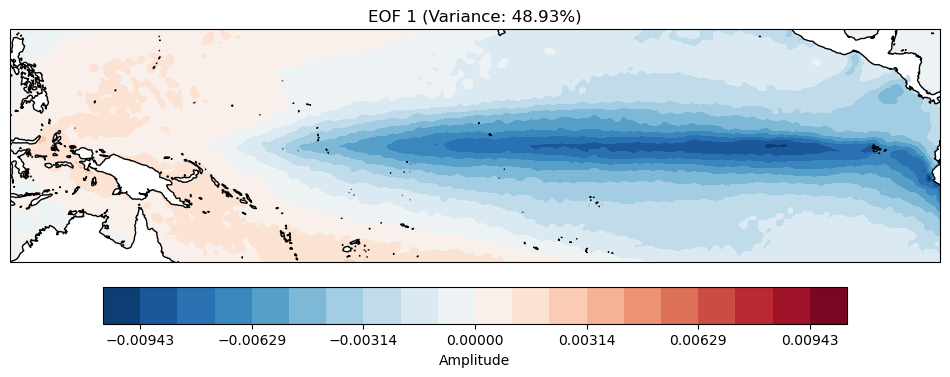

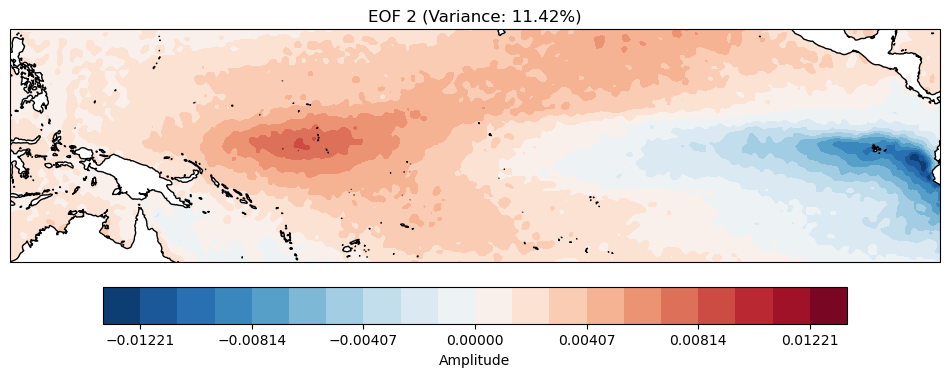

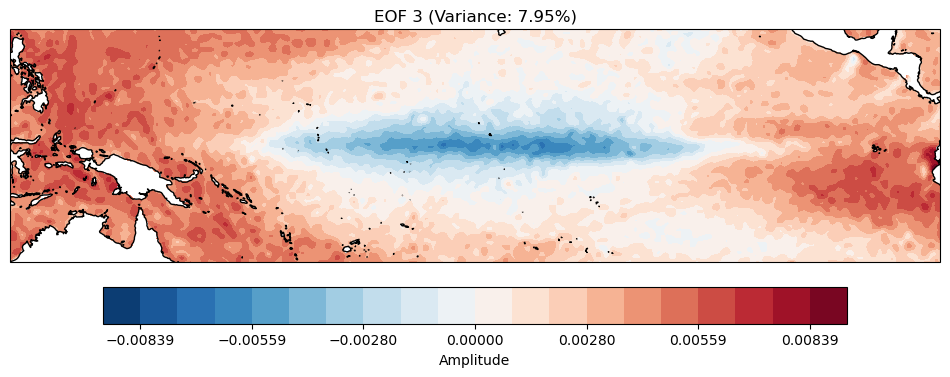

In [10]:
#Map Projections for Plotting
#central_longitude=180 keeps the Pacific in one piece across the dateline
proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()
lon = sst_anomaly.longitude
lat = sst_anomaly.latitude

#Plot for EOF Spatial Patterns
for i in range(3):
    fig = plt.figure(figsize=(12, 4))
    ax1 = plt.subplot(1, 1, 1, projection=proj)
    #Symmetric colour levels so that zero is white
    vmax = np.nanmax(np.abs(eofs[i, :, :]))
    levels = np.linspace(-vmax, vmax, 21)
    cf = ax1.contourf(lon, lat, eofs[i, :, :], levels=levels, cmap='RdBu_r', transform=data_crs)
    ax1.coastlines()
    ax1.set_extent([120, 280, -20, 20], crs=data_crs)
    ax1.set_title(f'EOF {i+1} (Variance: {variance_fraction[i]*100:.2f}%)')
    plt.colorbar(cf, ax=ax1, orientation='horizontal', label='Amplitude', shrink=0.8, pad=0.08)
    plt.show()

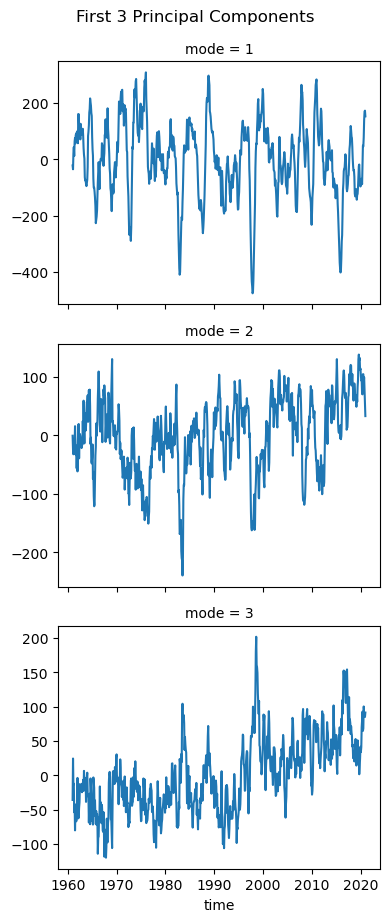

In [11]:
# Convert PCs to an xarray DataArray for convenient plotting
pc_da = xr.DataArray(
    pcs,
    dims=["valid_time", "mode"],
    coords={"valid_time": sst_anomaly.valid_time, "mode": [1, 2, 3]},
)

# Plot the first three principal components
pc_da.plot.line(x="valid_time", col="mode", col_wrap=1, sharey=False)
plt.suptitle("First 3 Principal Components", y=1.02)
plt.show()

## 7. PC–time correlation and interpretation

The sign of each EOF–PC pair is mathematically arbitrary: multiplying an EOF and its corresponding PC by −1 leaves the reconstruction unchanged. Therefore, the sign of PC1 should not be interpreted as a physical reversal of ENSO.

The following diagnostic calculates the Pearson correlation between each PC and a linear time index. A strong correlation indicates a linear temporal trend in that PC; it does not by itself establish the physical cause of the trend.

In [12]:
# Correlation of each PC with a linear time index
# This is a diagnostic only; the EOF analysis above is not detrended.
time_index = np.arange(pcs.shape[0])

for mode in range(3):
    r = np.corrcoef(time_index, pcs[:, mode])[0, 1]
    print(f"PC{mode + 1} vs. time correlation: r = {r:.3f}")

PC1 vs. time correlation: r = -0.172
PC2 vs. time correlation: r = 0.327
PC3 vs. time correlation: r = 0.656


## 8. Results and limitations

- **Variance explained:** EOF1 explains 48.93%, EOF2 11.42%, and EOF3 7.95% of the anomaly variance (68.30% combined).
- **EOF1** has an ENSO-like equatorial Pacific structure centred on the cold-tongue region. With the sign convention obtained here, the major El Niño episodes (1982–83, 1997–98 and 2015–16) appear as strongly negative PC1 values. The sign of an EOF–PC pair is arbitrary, so the opposite convention would be equally valid.
- **EOF2** shows an east–west contrast, and PC2 has sharp excursions during the strong 1982–83 and 1997–98 events. This is consistent with interpretations that distinguish eastern-Pacific El Niño events from other ENSO event structures, but a single EOF analysis does not prove that physical interpretation.
- **Trend:** The SST anomalies are not detrended. In the PC plots, PC3 shows the clearest long-term upward drift, with possibly weaker drift in PC2. The PC–time correlations printed above quantify this linear association; they do not establish its physical cause.